# Clase 1y2
 — Simulación de símbolos LoRa mediante chirps

En este notebook generamos símbolos LoRa a partir de la ecuación (3) del artículo, observamos sus muestras reales e imaginarias y el índice de fase de esa ecuación. Luego recuperamos el símbolo con *dechirp* y una FFT.

Ejecutá las celdas de arriba hacia abajo con `Shift + Enter`.

## Etapa 1 — Importar librerías y fijar parámetros

Usamos `numpy` para los cálculos numéricos y `matplotlib` para las gráficas. El ancho de banda se fija en 125 kHz.

In [20]:
import matplotlib.pyplot as plt
import numpy as np

B = 125_000  # ancho de banda [Hz]
MAX_SIMBOLOS = 5


## Etapa 2 — Definir la trama y validar la entrada

Cada símbolo se escribe como una cadena binaria. Su cantidad de bits determina el *spreading factor* (`SF`). Por ejemplo, `00100101` tiene 8 bits, así que `SF = 8` y hay $N = 2^{SF} = 256$ valores de símbolo posibles.

La función siguiente verifica que todos los símbolos tengan la misma longitud y solo contengan ceros y unos.

In [21]:
# simbolos = ["00100101"]
# Para probar una trama más larga, descomentá esta línea:
simbolos = ["00100101", "11110000", "00000011"]

def validar_simbolos(simbolos):
    if not isinstance(simbolos, (list, tuple)):
        raise TypeError("simbolos debe ser una lista o tupla de cadenas binarias")
    if not 1 <= len(simbolos) <= MAX_SIMBOLOS:
        raise ValueError(f"se admiten entre 1 y {MAX_SIMBOLOS} simbolos")
    if not all(isinstance(bits, str) and set(bits) <= {"0", "1"} for bits in simbolos):
        raise ValueError("cada simbolo debe ser una cadena formada solo por '0' y '1'")

    sf = len(simbolos[0])
    if sf == 0 or any(len(bits) != sf for bits in simbolos):
        raise ValueError("todos los simbolos deben tener la misma longitud y al menos un bit")
    return sf

sf = validar_simbolos(simbolos)
N = 2**sf
Ts = N / B
print(f"SF={sf}, N={N}, duración de símbolo Ts={Ts * 1e3:.3f} ms")


SF=8, N=256, duración de símbolo Ts=2.048 ms


## Etapa 3 — Construir las muestras del chirp

El artículo define el chirp sólo en tiempo discreto: para $k=0,…,N-1$, $c_s[k]=N^{-1/2}e^{j2π[((s+k) mod N)k/N]}$. La celda siguiente implementa directamente esa ecuación y grafica únicamente sus `N` muestras.

In [22]:
def modular_simbolo(valor, k, N):
    """Implementa la ecuación (3) para k=0,...,N-1."""
    fase_discreta = ((valor + k) % N) * k / N
    chirp = np.exp(1j * 2 * np.pi * fase_discreta) / np.sqrt(N)
    tiempo = k / B
    indice_ecuacion = np.mod(valor + k, N) * B / N
    return chirp, tiempo, chirp.real, chirp.imag, indice_ecuacion


## Etapa 4 — Modular y construir la señal recibida

Primero convertimos cada cadena binaria a su valor decimal y modulamos cada una. En esta primera prueba ideal, la señal recibida es exactamente el chirp transmitido; más adelante se podrá reemplazar por una señal con ruido.

In [23]:
k = np.arange(N)
valores_enviados = [int(bits, 2) for bits in simbolos]
recibidas = []
vistas = []

for valor in valores_enviados:
    chirp, tiempo, real, imaginaria, frecuencia = modular_simbolo(valor, k, N)
    recibidas.append(chirp)  # Canal ideal: r[k] = c[k].
    vistas.append((tiempo, real, imaginaria, frecuencia))

print(f"Se construyeron {len(recibidas)} señales recibidas ideales.")


Se construyeron 3 señales recibidas ideales.


## Etapa 5 — Demodular con down-chirp y FFT

El receptor recibe $r[k]$. En un canal ideal, $r[k]=c_s[k]$; con ruido, sería $r[k]=c_s[k]+w[k]$. Multiplicar muestra a muestra por el *down-chirp* $e^{-j2\pi k^2/N}$ cancela el término cuadrático del chirp. Lo que queda es un tono complejo $e^{j2\pi sk/N}$, cuya FFT concentra toda la energía en el bin $s$.

Por eso el símbolo estimado es el índice de mayor energía: `argmax(abs(FFT)**2)`.

In [24]:
def demodular_simbolo(recibida):
    """Devuelve el símbolo estimado, la señal dechirpeada y su FFT."""
    recibida = np.asarray(recibida, dtype=complex)
    N_recibido = len(recibida)
    if N_recibido == 0:
        raise ValueError("la señal recibida no puede estar vacía")

    k_recibido = np.arange(N_recibido)
    downchirp = np.exp(-1j * 2 * np.pi * k_recibido**2 / N_recibido)
    dechirpeada = recibida * downchirp
    espectro = np.fft.fft(dechirpeada)
    simbolo_estimado = int(np.argmax(np.abs(espectro)**2))
    return simbolo_estimado, dechirpeada, espectro

valores_estimados = [demodular_simbolo(r)[0] for r in recibidas]
assert valores_estimados == valores_enviados

for bits, enviado, estimado in zip(simbolos, valores_enviados, valores_estimados):
    print(f"{bits} → s={enviado}; detectado={estimado}")


00100101 → s=37; detectado=37
11110000 → s=240; detectado=240
00000011 → s=3; detectado=3


## Etapa 6 — Visualizar el resultado

Las dos primeras gráficas muestran las componentes real e imaginaria de las `N` muestras. La tercera muestra el índice $[(s+k) mod N]B/N$ que aparece en la ecuación (3); no es una extensión continua ni una medición de frecuencia instantánea. Si agregás más símbolos en la etapa 2, las líneas punteadas separan la duración de cada uno.

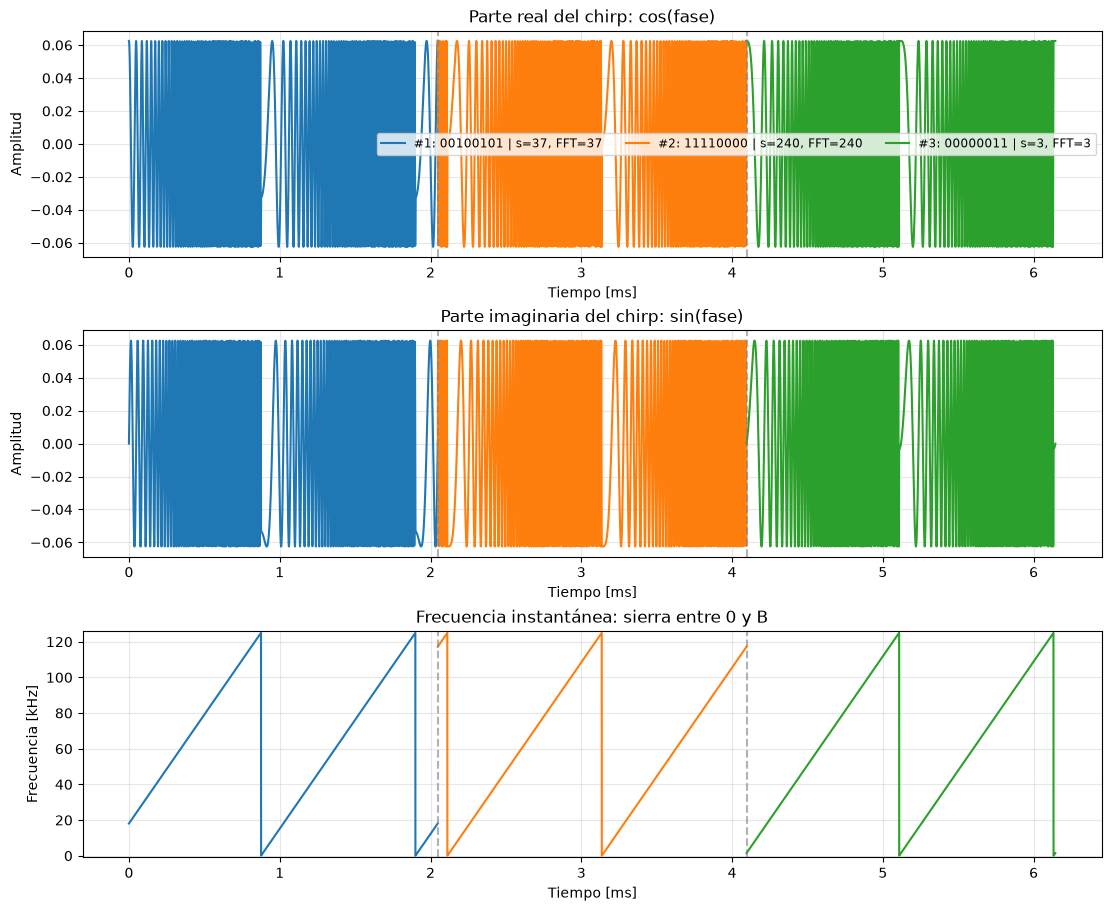

In [25]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), constrained_layout=True)

for indice, ((tiempo, real, imaginaria, frecuencia), bits, enviado, estimado) in enumerate(
    zip(vistas, simbolos, valores_enviados, valores_estimados)
):
    tiempo = indice * Ts + tiempo
    etiqueta = f"#{indice + 1}: {bits} | s={enviado}, FFT={estimado}"
    axes[0].plot(tiempo * 1e3, real, label=etiqueta)
    axes[1].plot(tiempo * 1e3, imaginaria, label=etiqueta)
    axes[2].plot(tiempo * 1e3, frecuencia / 1e3)

limites_ms = np.arange(len(vistas) + 1) * Ts * 1e3
for limite in limites_ms[1:-1]:
    for ax in axes:
        ax.axvline(limite, color="gray", linestyle="--", alpha=0.6)

axes[0].set(title="Parte real del chirp: cos(fase)", xlabel="Tiempo [ms]", ylabel="Amplitud")
axes[1].set(title="Parte imaginaria del chirp: sin(fase)", xlabel="Tiempo [ms]", ylabel="Amplitud")
axes[2].set(title="Índice [(s + k) mod N] de la ecuación (3)", xlabel="Tiempo [ms]", ylabel="Índice × B/N [kHz]")
axes[2].set_ylim(-1, B / 1e3 + 1)

for ax in axes:
    ax.grid(True, alpha=0.3)
axes[0].legend(ncol=min(len(vistas), 3), fontsize="small")
plt.show()


## Error
Pe = BER = n° bits errados / n° bits totales

In [40]:
def calc_error(bits_enviados, bits_recibidos):
    """Devuelve el BER: bits distintos dividido por bits enviados."""
    if len(bits_enviados) != len(bits_recibidos):
        raise ValueError("las dos secuencias deben tener la misma longitud")
    if not bits_enviados:
        raise ValueError("la secuencia de bits no puede estar vacía")

    bits_errados = sum(
        bit_enviado != bit_recibido
        for bit_enviado, bit_recibido in zip(bits_enviados, bits_recibidos)
    )
    return bits_errados / len(bits_enviados)

## Etapa 7 — Pico que recupera el símbolo

Cada fila es la energía de la FFT después de multiplicar la señal recibida por el *down-chirp*. En el caso ideal, toda la energía queda concentrada en el bin del símbolo transmitido.

37  en binario es  00100101  el que se mandó fue  00100101
Probabilidad de error (BER) 0.0
240  en binario es  11110000  el que se mandó fue  11110000
Probabilidad de error (BER) 0.0
3  en binario es  00000011  el que se mandó fue  00000011
Probabilidad de error (BER) 0.0


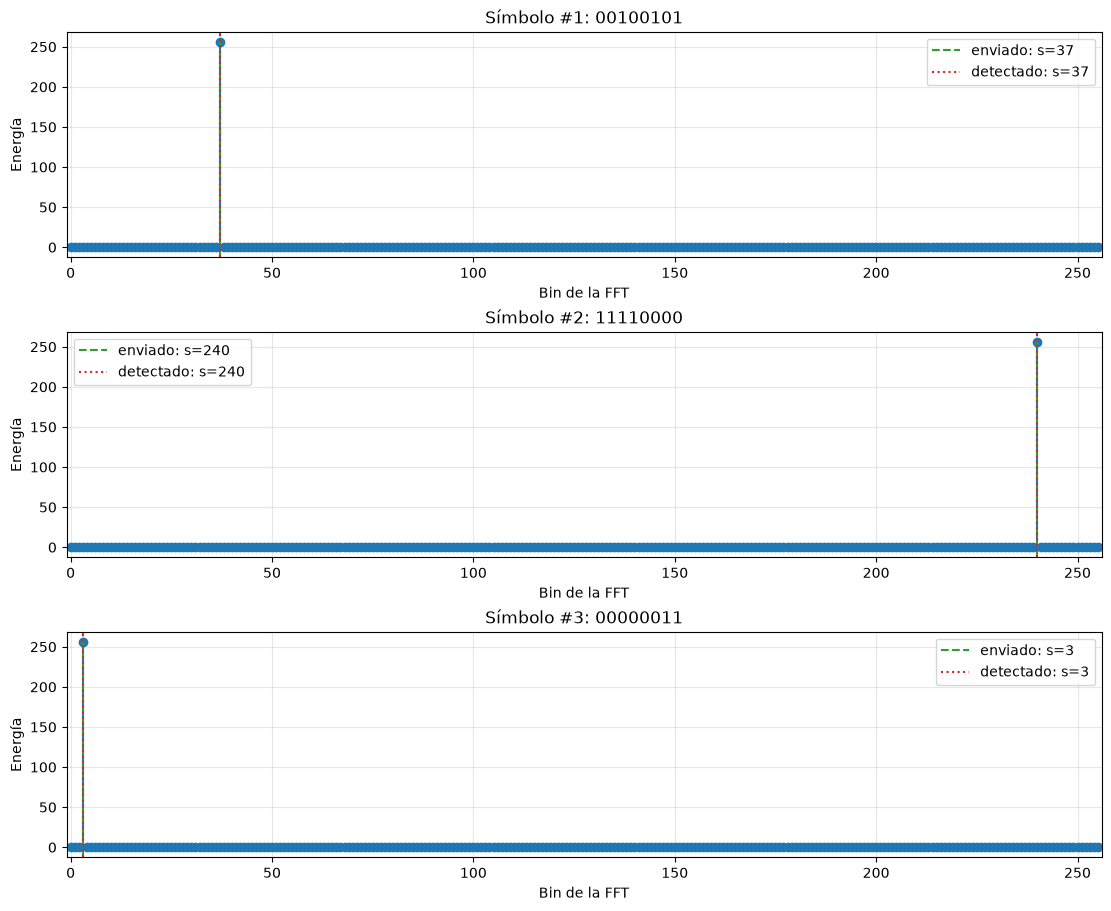

In [42]:
resultados = [demodular_simbolo(recibida) for recibida in recibidas]

fig, axes = plt.subplots(len(resultados), 1, figsize=(11, 3 * len(resultados)), squeeze=False, constrained_layout=True)


for indice, ((estimado, _, espectro), bits, enviado) in enumerate(
    zip(resultados, simbolos, valores_enviados)
):
    energia = np.abs(espectro)**2
    ax = axes[indice, 0]
    ax.stem(np.arange(N), energia, basefmt=" ")
    ax.axvline(enviado, color="tab:green", linestyle="--", label=f"enviado: s={enviado}")
    ax.axvline(estimado, color="tab:red", linestyle=":", label=f"detectado: s={estimado}")
    ax.set(title=f"Símbolo #{indice + 1}: {bits}", xlabel="Bin de la FFT", ylabel="Energía")
    ax.set_xlim(-1, N)
    ax.grid(True, alpha=0.3)
    ax.legend()

    print(estimado, " en binario es ", format(estimado, f"0{sf}b"), " el que se mandó fue ", format(enviado, f"0{sf}b"))
    bits_detectados = format(estimado, f"0{sf}b")
    print("Probabilidad de error (BER)", calc_error(format(enviado, f"0{sf}b"), bits_detectados))

plt.show()


## Para experimentar

Volvé a la etapa 2 y probá con dos o tres símbolos de 8 bits. También podés cambiar el valor de `B` y observar cómo cambia $T_s=N/B$. Todos los símbolos de una misma simulación deben tener la misma cantidad de bits.

## Potencia de la señal recibida

La potencia promedio se obtiene promediando $|r[k]|^2$. La suma de esos valores es la energía discreta total del símbolo.

In [37]:
for indice, recibida in enumerate(recibidas, start=1):
    potencia_promedio = np.mean(np.abs(recibida)**2)
    energia_total = np.sum(np.abs(recibida)**2)
    print(
        f"Símbolo #{indice}: potencia promedio = {potencia_promedio:.6f}; "
        f"energía total = {energia_total:.6f}"
    )


Símbolo #1: potencia promedio = 0.003906; energía total = 1.000000
Símbolo #2: potencia promedio = 0.003906; energía total = 1.000000
Símbolo #3: potencia promedio = 0.003906; energía total = 1.000000


## Agregar ruido complejo y medir su potencia

Se toma el primer chirp transmitido y se suma ruido $w\sim\mathcal{CN}(0,\sigma^2 I)$. Por ello, la potencia teórica de cada muestra de ruido es $\sigma^2$.

In [ ]:
sigma = 0.02  # Desvío estándar complejo: potencia teórica del ruido = sigma**2.
generador = np.random.default_rng(2026)  # Semilla fija: permite repetir el ejemplo.

senal_transmitida = recibidas[0]
cantidad_muestras = len(senal_transmitida)
ruido = sigma / np.sqrt(2) * (
    generador.standard_normal(cantidad_muestras)
    + 1j * generador.standard_normal(cantidad_muestras)
)
senal_ruidosa = senal_transmitida + ruido

potencia_senal = np.mean(np.abs(senal_transmitida)**2)
potencia_ruido_medida = np.mean(np.abs(ruido)**2)
potencia_recibida = np.mean(np.abs(senal_ruidosa)**2)
snr_teorica_db = 10 * np.log10(potencia_senal / sigma**2)
snr_medida_db = 10 * np.log10(potencia_senal / potencia_ruido_medida)

print(f"Potencia de la señal:       {potencia_senal:.6f}")
print(f"Potencia teórica del ruido: {sigma**2:.6f}")
print(f"Potencia medida del ruido:  {potencia_ruido_medida:.6f}")
print(f"Potencia de señal ruidosa:  {potencia_recibida:.6f}")
print(f"SNR teórica: {snr_teorica_db:.2f} dB")
print(f"SNR medida:  {snr_medida_db:.2f} dB")


## Obtener los parámetros del ruido a partir de SNR

La función recibe una SNR objetivo en dB y usa la potencia de la señal calculada antes. A partir de $\mathrm{SNR}_{dB}=10\log_{10}(P_s/P_n)$ despeja $P_n$ y luego calcula $\sigma=\sqrt{P_n}$.

In [39]:
def parametros_ruido_desde_snr(snr_db):
    """Devuelve potencia de ruido y sigma para la SNR objetivo en dB."""
    if not np.isfinite(snr_db):
        raise ValueError("snr_db debe ser un número finito")

    snr_lineal = 10**(snr_db / 10)
    potencia_ruido = potencia_senal / snr_lineal
    sigma = np.sqrt(potencia_ruido)
    return potencia_ruido, sigma

snr_objetivo_db = 10
potencia_ruido_objetivo, sigma_objetivo = parametros_ruido_desde_snr(snr_objetivo_db)

print(f"SNR objetivo: {snr_objetivo_db:.2f} dB")
print(f"Potencia de ruido necesaria: {potencia_ruido_objetivo:.6f}")
print(f"Sigma para CN(0, sigma**2 I): {sigma_objetivo:.6f}")


SNR objetivo: 10.00 dB
Potencia de ruido necesaria: 0.000391
Sigma para CN(0, sigma**2 I): 0.019764
